In [1]:
# Imports
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import os
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from scipy.interpolate import griddata
import matplotlib.cm as cm
import matplotlib.colors as colors
import imageio
import glob
import skgstat as skg
from scipy.spatial.distance import cdist

In [2]:
# In [2]: Load and Prepare Data
# Load the pre-processed data
merged_gdf = pd.read_feather('../data/processed/merged_gdf.feather', use_threads=False)
merged_gdf = gpd.GeoDataFrame(merged_gdf, geometry=gpd.points_from_xy(merged_gdf.longitude, merged_gdf.latitude), crs='EPSG:4326')

# Filter summer bottom do data
summer_bottom_df = merged_gdf[
    (merged_gdf['season'] == 'Summer') &
    (merged_gdf['saisuipoin'] == 2)
].dropna(subset=['do_']).copy()

print(summer_bottom_df.head())

      uniqueid zettaicode locationna wancode prefectuei  watercode renban  \
4   0000001734   00002811      兵庫県11      03         28        301     11   
12  0000001742   00002823      兵庫県23      03         28        301     23   
19  0000001678   00000272       大阪府2      03         27        301      2   
27  0000001686   00000275       大阪府5      03         27        301      5   
35  0000001694   00002725      大阪府25      03         27        301     25   

    nendo  survey_ym  surveyyear  ...   doc  doc2  dataflag  scale  \
4    1981 1981-06-01        1981  ...  None   0.0         1     -1   
12   1981 1981-06-01        1981  ...  None   0.0         1     -1   
19   1981 1981-06-01        1981  ...  None   0.0         1     -1   
27   1981 1981-06-01        1981  ...  None   0.0         1     -1   
35   1981 1981-06-01        1981  ...  None   0.0         1     -1   

                      geometry  year   watermass_name   division  \
4     POINT (135.33056 34.695)  1981  Seto Inlan

In [3]:
print(summer_bottom_df.columns)

Index(['uniqueid', 'zettaicode', 'locationna', 'wancode', 'prefectuei',
       'watercode', 'renban', 'nendo', 'survey_ym', 'surveyyear', 'surveymont',
       'surveyday', 'surveyhour', 'surveymini', 'saisuipoin', 'latitude',
       'longitude', 'weather', 'cloud', 'fuko', 'fusoku', 'temp', 'color',
       'saisuidept', 'depth', 'clearness', 'wtemp', 'ph', 'ph2', 'do_', 'do_2',
       'salt', 'salt2', 'cod', 'cod2', 'rcod', 'rcod2', 'nh4n', 'nh4n2',
       'no2n', 'no2n2', 'no3n', 'no3n2', 'tn', 'tn2', 'po4p', 'po4p2', 'tp',
       'tp2', 'chlorophyl', 'chloroph_1', 'feiochin', 'feiochin2', 'toc',
       'toc2', 'doc', 'doc2', 'dataflag', 'scale', 'geometry', 'year',
       'watermass_name', 'division', 'details', 'season'],
      dtype='object')


'zettaicode' colummn is the code assigned for each unique sampling stations. 'geometry' is the column that represents each unique sampling points, that already contains lat and lon. Now let's make a yearly time series data frame for each of these sampling points.

In [4]:
unique_points = summer_bottom_df['zettaicode'].drop_duplicates().tolist() # or .unique() can also work
print(unique_points)
print(f"Number of unique sampling points: {len(unique_points)}")

['00002811', '00002823', '00000272', '00000275', '00002725', '00036147', '00044533', '00044575', '00044578', '00044527', '00033182', '00035565', '00033237', '00035562', '00033224', '00035588', '00033241', '00033248', '00033204', '00035598', '00033277', '00034285', '00034310', '00033276', '00034332', '00034344', '00038667', '00035582', '00038671', '00035613', '00035626', '00035707', '00040632', '00003695', '00003698', '00034312', '00036103', '00038674', '00036164', '00044594', '00044529', '00044677', '00003089', '00040714', '00040715', '00036110', '00028169', '00035550', '00044531', '00037170', '00003086', '00044605', '00002750', '00002758', '00037179', '00035521', '00035522', '00034391', '00037213', '00035484', '00037181', '00037195', '00034423', '00037263', '00035512', '00038469', '00037238', '00044690', '00037250', '00037254', '00037298', '00038274', '00038647', '00038665', '00002848', '00028119', '00035486', '00038441', '00038495', '00002737', '00002744', '00044679', '00044680', '00

In [5]:
# make a new column to show the duplicate entries per 'zettaicode and 'year'
dup_summary = summer_bottom_df.groupby(['zettaicode', 'year']).size().reset_index(name='counts')
# Identify the 'zettaicode' that has multiple entries in a single year
dup_mask = dup_summary['counts'] > 1

# make a list of all the zettaicodes that have duplicates
dup_stations = dup_summary.loc[dup_mask, 'zettaicode'].unique().tolist()
print(f"number of points that have duplicate entries: {len(dup_stations)}")
print(dup_stations)

number of points that have duplicate entries: 16
['00003064', '00003078', '00003079', '00003086', '00003089', '00037170', '00037179', '00037181', '00037195', '00037213', '00037238', '00037250', '00037254', '00037263', '00037298', '00038308']


In [6]:
# test check one of the 'zettaicode'
dupe_test = summer_bottom_df[
    summer_bottom_df['zettaicode'] == '00003064'][
    ['zettaicode', 'surveyyear', 'surveymont', 'do_']
]

duplicates_only_df = dupe_test[dupe_test.duplicated(subset=['surveyyear'], keep=False)]

In [7]:
# create a loop to make a summary dataframe with all the years that have duplicate entries
duplicate_stations_df = summer_bottom_df[
    summer_bottom_df['zettaicode'].isin(dup_stations)
]
pd.set_option('display.max_rows', 0)
print(duplicate_stations_df[['zettaicode', 'surveyyear', 'surveymont', 'do_']].sort_values('zettaicode'))

      zettaicode  surveyyear  surveymont  do_
19839   00003064        2001           7  5.8
30800   00003064        2012           7  6.5
2547    00003064        1983           8  6.5
28484   00003064        2009           7  6.6
3406    00003064        1984           7  7.2
39496   00003064        2021           7  6.9
4082    00003064        1985           6  8.3
4083    00003064        1985           7  6.1
9954    00003064        1991           7  8.0
...          ...         ...         ...  ...
38055   00038308        2019           7  6.6
21364   00038308        2002           7  6.5
4784    00038308        1985           7  8.8
30718   00038308        2012           7  6.1
30508   00038308        2011           7  8.7
22117   00038308        2003           7  6.8
39063   00038308        2020           7  6.4
17485   00038308        1998           7  6.8
41073   00038308        2022           7  6.1

[698 rows x 4 columns]


In [8]:
# Create dictionary grouped by 'zettaicode'
# For each group, select 'year' and 'do_', then set 'year' as the index
points_dict = {name: group[['year', 'do_']].set_index('year')
    for name, group in summer_bottom_df.groupby('zettaicode')}

This code uses a dictionary function that uses curl bracket ``{}``. This allows for access of a certain data frame from the dictionary by using the dictionary key to extract it.

In [9]:
# For example
point1 = points_dict['00002725']
point2 = points_dict['00002823']
point3 = points_dict['00000272']
point4 = points_dict['00000275']

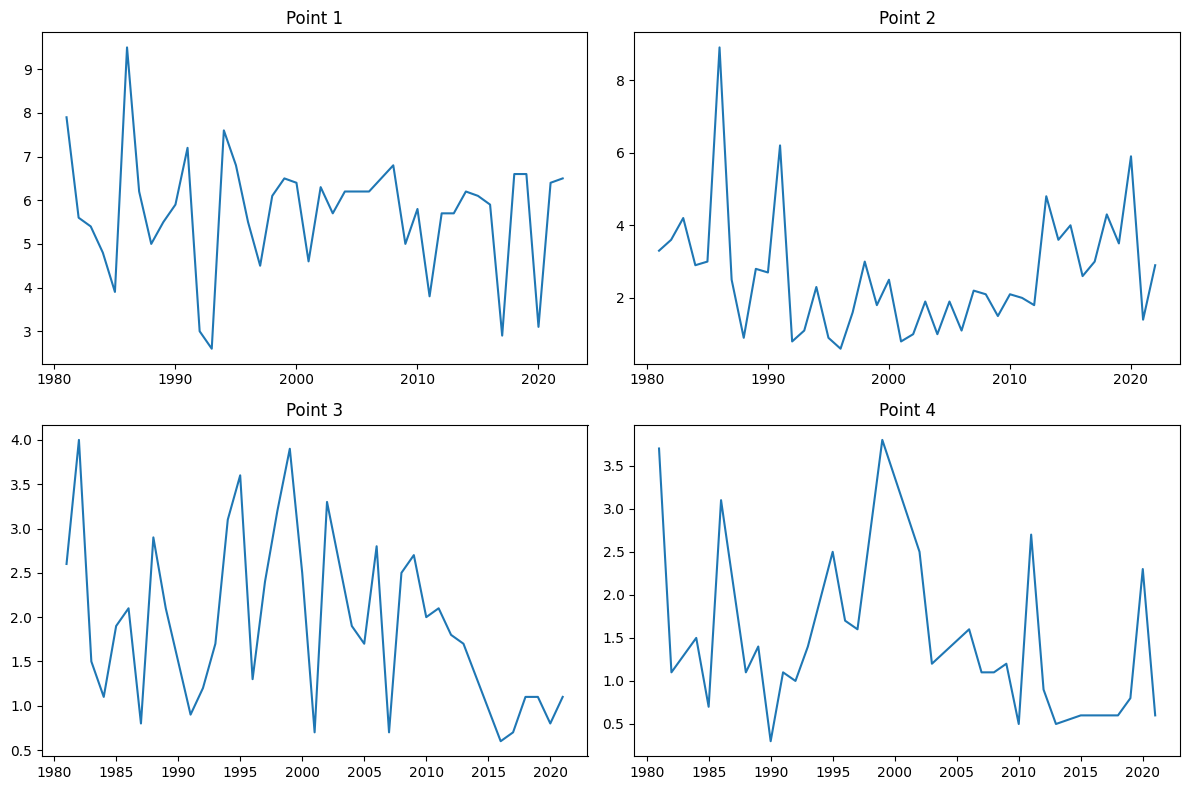

In [10]:
# plot 4 points in a 2x2 grid subplot
fig, axs = plt.subplots(2, 2, figsize=(12, 8))
axs[0, 0].plot(point1)
axs[0, 0].set_title('Point 1')

axs[0, 1].plot(point2)
axs[0, 1].set_title('Point 2')

axs[1, 0].plot(point3)
axs[1, 0].set_title('Point 3')

axs[1, 1].plot(point4)
axs[1, 1].set_title('Point 4')

plt.tight_layout()
plt.show()

AI prompt for next step:

I want to make a loop to generate a yearly summer bottom DO list for all of the unique sampling sites. So the index is the sampling points code (either 'zettaicode' or 'geometry'). Maybe I need to assign a unique number for each of them. After that, make a list of every DO value from each years. So basically I just need to transpose the data I already have so the index is the sampling points instead of years.

In [11]:
# combine all of the points dataframes into a single dataframe, with the index as 'zettaicode' and columns as years
yearly_do = []
for zettaicode, df in points_dict.items():
    numeric_index = pd.to_numeric(df.index, errors='coerce')    
    series = df['do_'].groupby(numeric_index).mean().rename(zettaicode)
    yearly_do.append(series)

yearly_do_df = pd.concat(yearly_do, axis=1).T

In [12]:
# 1. Count non-missing values for each row (station)
non_missing_counts = yearly_do_df.count(axis=1)

# 2. Count missing (NaN) values for each row (station)
missing_counts = yearly_do_df.isna().sum(axis=1)

# 3. Combine them into a new summary DataFrame for easy viewing
row_summary_df = pd.DataFrame({
    'non_missing_years': non_missing_counts,
    'missing_years': missing_counts
})

# 4. Optional: Add a 'completeness' percentage
total_years = len(yearly_do_df.columns)
row_summary_df['completeness_%'] = (row_summary_df['non_missing_years'] / total_years) * 100

# 5. Optional: Sort by the most incomplete stations first
row_summary_df = row_summary_df.sort_values(by='missing_years', ascending=False)

In [13]:
# Create a new lookup table that contains the coordinate of each station

station_coords = summer_bottom_df[['zettaicode', 'geometry', 'latitude', 'longitude']].drop_duplicates(subset=['zettaicode'])

In [14]:
# Test: create a list of stations that have a valid  DO recording for one year
maskVA_1990 = yearly_do_df[1990].notna()
va_do_1990 = yearly_do_df.index[maskVA_1990].tolist()

In [15]:
# Calculating the distance between one target station and all other stations with valid DO

target_gdf = station_coords[station_coords['zettaicode'] == '00003064']
source_gdf = station_coords[station_coords['zettaicode'].isin(va_do_1990)]

# Reproject CRS
target_gdf_meters = target_gdf.to_crs(epsg=32653)
source_gdf_meters = source_gdf.to_crs(epsg=32653)

target_point_meters = target_gdf_meters.geometry.iloc[0]

# Calculate the distance from target point to all source point
distances_in_meters = source_gdf_meters.geometry.distance(target_point_meters)
source_gdf_meters['distance_to_target_m'] = distances_in_meters

In [16]:
# combine the two data frame so I have the distance column and DO column
do_1990_series = yearly_do_df[1990].rename('do_1990')
do_df_1990 = source_gdf_meters.join(do_1990_series, on='zettaicode')

In [17]:
# calculate 'weight' column
x = do_df_1990['distance_to_target_m']
xd = 48.67 * 1000  # 48,670 meters
do_df_1990['weight'] = np.exp(-(x/xd)**2)

# Calculate the DO weighted average (Σ(wi * DOi) / Σwi)
do_df_1990['do_1990'] = pd.to_numeric(do_df_1990['do_1990'], errors='coerce')
clean_df = do_df_1990.dropna(subset=['do_1990'])
do_values = clean_df['do_1990'].to_numpy(dtype=float)
weights = clean_df['weight'].to_numpy(dtype=float)
weighted_average = np.average(do_values, weights=weights)

print(weighted_average)

5.638897885570628


In [18]:
# Reverse mask: create a list of stations that DOESN'T HAVE a valid  DO recording for one year
maskNA_1990 = yearly_do_df[1990].isna()
na_do_1990 = yearly_do_df.index[maskNA_1990].tolist()

In [19]:
import numpy as np
from scipy.spatial.distance import cdist

# --- 1. Setup ---
# Define decorrelation distance in meters (from your analysis)
xd = 48.67 * 1000 # 71.87 km * 1000

# Create a copy of your data to fill in the gaps
yearly_do_filled = yearly_do_df.copy()

# Create a meter-based coordinate lookup table, indexed by zettaicode
# This is done ONCE outside the loop for efficiency
try:
    station_coords_meters = station_coords.set_index('zettaicode').to_crs(epsg=32653)
except Exception as e:
    print(f"Error setting up station_coords: {e}")
    # Handle this error if station_coords is not set up correctly

# --- 2. Main Loop ---
# Loop over each year (each column in your DataFrame)
for year in yearly_do_filled.columns:
    # print(f"--- Processing year: {year} ---")
    
    # Step 1: Create a list of source stations (with data)
    source_mask = yearly_do_filled[year].notna()
    source_stations = yearly_do_filled.index[source_mask]
    
    # Step 2: Create a list of target stations (NaN)
    target_mask = yearly_do_filled[year].isna()
    target_stations = yearly_do_filled.index[target_mask]

    # Check if there's any work to do
    if target_stations.empty:
        print("    No missing values to fill.")
        continue
    if source_stations.empty:
        print("    No source data available to fill gaps.")
        continue
        
    # --- Efficiently get all data for this year ---
    try:
        # Get geometry and DO values for all sources
        source_gdf = station_coords_meters.loc[source_stations]
        source_do_values = yearly_do_filled.loc[source_stations, year].values
        
        # Get geometry for all targets
        target_gdf = station_coords_meters.loc[target_stations]
    
    except KeyError as e:
        print(f"    Skipping {year}: Zettaicode {e} is in 'yearly_do_df' but not in 'station_coords'.")
        continue
        
    # Prepare coordinate arrays for cdist
    source_coords = np.array([geom.coords[0] for geom in source_gdf.geometry])
    target_coords = np.array([geom.coords[0] for geom in target_gdf.geometry])

    # Step 3: Calculate the distances ('d') from all targets to all sources
    # This creates a (num_targets x num_sources) matrix
    distance_matrix = cdist(target_coords, source_coords, metric='euclidean')
    
    # Step 4: Calculate the Gaussian weights (e^-(d/z)²)
    weights_matrix = np.exp(-(distance_matrix / xd)**2)
    
    # Step 5: Calculate the final weighted average to fill the gap
    # This is the formula: Σ(wi * DOi) / Σwi
    
    # Calculate Σ(wi * DOi) using matrix multiplication
    weighted_sums = np.dot(weights_matrix, source_do_values)
    
    # Calculate Σ(wi) for each target
    sum_of_weights = np.sum(weights_matrix, axis=1)
    
    # Calculate the average. Use np.where to avoid dividing by zero
    # if a target is too far from all sources (sum_of_weights == 0)
    weighted_avg_do = np.where(
        sum_of_weights > 0,              # Condition: if sum of weights is not zero
        weighted_sums / sum_of_weights,  # Value if True: calculate the average
        np.nan                           # Value if False: return NaN
    )
    
    # --- Fill the gaps in your copied DataFrame ---
    yearly_do_filled.loc[target_stations, year] = weighted_avg_do
    
    # print(f"    Successfully interpolated {len(target_stations)} values.")

print("\n--- Gap filling complete ---")

    No missing values to fill.
    No missing values to fill.
    No missing values to fill.
    No missing values to fill.
    No missing values to fill.

--- Gap filling complete ---


In [20]:
# Save the new data frame into a Feather file

yearly_do_filled.to_feather('../data/processed/yearly_do_filled.feather')
print("DataFrame saved to '../data/processed/yearly_do_filled.feather'")

DataFrame saved to '../data/processed/yearly_do_filled.feather'


Now let's try to calculate the hypoxia frequency across the different water masses in summer.

In [21]:
# 1. Create a Hypoxia Mask (True = Hypoxic, False = Not Hypoxic)
# Threshold is DO < 2.0 mg/L
hypoxia_threshold = 4.0
is_hypoxic_df = yearly_do_filled < hypoxia_threshold

# 2. Get the 'division' (Water Mass) information for each station
# We extract unique pairs of zettaicode and division from your original dataframe
station_meta = summer_bottom_df[['zettaicode', 'division']].drop_duplicates()
station_meta = station_meta.set_index('zettaicode')

# 3. Join the division info to your hypoxia boolean dataframe
# We use inner join to ensure we only analyze stations we have metadata for
hypoxia_with_division = is_hypoxic_df.join(station_meta, how='inner')

In [22]:
# Calculate the frequency (mean) across the columns (years) for each row (station)
# Multiply by 100 to get a percentage
station_hypoxia_freq = is_hypoxic_df.mean(axis=1) * 100

print("Hypoxia Frequency per Station (% of years):")
print(station_hypoxia_freq.head())

Hypoxia Frequency per Station (% of years):
00000272    90.476190
00000275    71.428571
00002725    14.285714
00002737     2.380952
00002744     2.380952
dtype: float64


In [23]:
# Group by 'division' and calculate the mean for each year column
# This gives the proportion of hypoxic stations per division per year
yearly_hypoxia_by_division = hypoxia_with_division.groupby('division').mean() * 100

print("Yearly Hypoxia Frequency by Water Mass (%):")
print(yearly_hypoxia_by_division)

# Optional: Transpose for easier reading if you have many years
# print(yearly_hypoxia_by_division.T)

Yearly Hypoxia Frequency by Water Mass (%):
                    1981  1982       1983       1984       1985       1986  \
division                                                                     
Aki Nada        0.000000   0.0  12.500000   0.000000  12.500000   0.000000   
Bingo Nada      0.000000   0.0   0.000000   0.000000   0.000000   0.000000   
Bisan Seto      0.000000   0.0   0.000000   0.000000   0.000000   0.000000   
Bungo Channel   0.000000   0.0   0.000000   0.000000   0.000000   0.000000   
Harima Nada    14.285714   0.0  35.714286   0.000000  21.428571  14.285714   
Hibiki Nada     0.000000   0.0   0.000000   0.000000   0.000000   0.000000   
Hiroshima Bay   0.000000   0.0  11.111111   0.000000  11.111111   0.000000   
Hiuchi Nada     0.000000   0.0  11.111111   0.000000   0.000000   0.000000   
Iyo Nada        0.000000   0.0   0.000000   0.000000   0.000000   0.000000   
Kii Channel     0.000000   0.0   0.000000   0.000000   0.000000   0.000000   
Osaka Bay      40.00

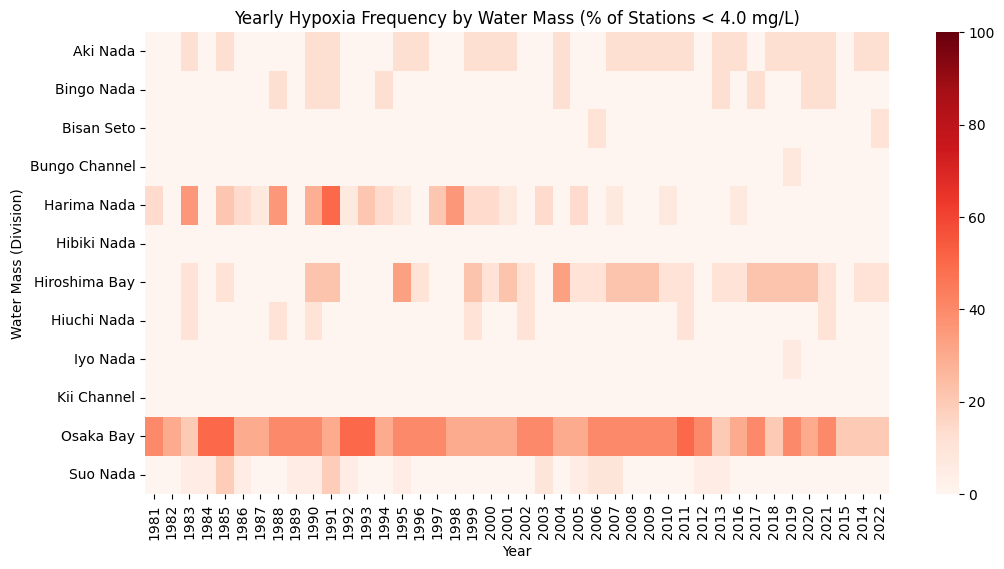

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

# Heatmap: Good for seeing "hotspots" of hypoxia over time
sns.heatmap(yearly_hypoxia_by_division, cmap='Reds', vmin=0, vmax=100, annot=False)

plt.title(f'Yearly Hypoxia Frequency by Water Mass (% of Stations < {hypoxia_threshold} mg/L)')
plt.xlabel('Year')
plt.ylabel('Water Mass (Division)')
plt.show()

It seems that Osaka Bay is the most affected area, followed by Harima Nada, Hiroshima Bay, Aki Nada, and Hiuchi Nada